## Импорты и настройки


In [1]:
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 13
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


def existing_path(*variants: str) -> Path:
    for variant in variants:
        path = Path(variant)
        if path.exists():
            return path
    return Path(variants[0])


def local_dataset_file(filename: str) -> Path:
    path = existing_path(f"data/{filename}", f"../data/{filename}")
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден {filename}. Скачай его один раз в папку data рядом с ноутбуком."
        )
    return path


print(f"Device: {DEVICE}")


Device: cpu


## Общие функции


In [2]:
def activation(name: str) -> nn.Module:
    activations = {
        "relu": nn.ReLU(),
        "tanh": nn.Tanh(),
        "mish": nn.Mish(),
        "elu": nn.ELU(),
        "leaky_relu": nn.LeakyReLU(0.1),
    }
    return activations[name]


def make_mlp(input_size: int, hidden: list[int], activations: list[str], output_size: int) -> nn.Sequential:
    layers = []
    prev = input_size
    for width, act in zip(hidden, activations):
        layers.append(nn.Linear(prev, width))
        layers.append(activation(act))
        prev = width
    layers.append(nn.Linear(prev, output_size))
    return nn.Sequential(*layers)


def make_loader(x: np.ndarray, y: np.ndarray, batch_size: int = 64, shuffle: bool = True) -> DataLoader:
    dataset = TensorDataset(torch.tensor(x, dtype=torch.float32), torch.tensor(y))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


In [3]:
def count_correct(logits: torch.Tensor, y: torch.Tensor, task: str) -> int:
    if task == "regression":
        return 0
    if task == "multiclass":
        return int((logits.argmax(dim=1) == y).sum().item())
    if task == "binary_probability":
        pred = (logits.view(-1) >= 0.5).float()
    else:
        pred = (torch.sigmoid(logits).view(-1) >= 0.5).float()
    return int((pred == y.view(-1)).sum().item())


def evaluate(model: nn.Module, loader: DataLoader, criterion: nn.Module, task: str) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = criterion(out, y)
            total_loss += float(loss.item()) * len(x)
            correct += count_correct(out, y, task)
            total += len(x)
    accuracy = correct / total if task != "regression" else 0.0
    return total_loss / total, accuracy


def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    task: str,
    epochs: int = 10,
    lr: float = 1e-3,
) -> dict[str, list[float]]:
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}

    for _ in range(epochs):
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            train_loss += float(loss.item()) * len(x)
            train_correct += count_correct(out, y, task)
            train_total += len(x)

        val_loss, val_acc = evaluate(model, val_loader, criterion, task)
        history["loss"].append(train_loss / train_total)
        history["acc"].append(train_correct / train_total if task != "regression" else 0.0)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

    return history


In [4]:
def plot_history(history: dict[str, list[float]], title: str, show_accuracy: bool = True) -> None:
    cols = 2 if show_accuracy else 1
    fig, axes = plt.subplots(1, cols, figsize=(10 if show_accuracy else 5, 3))
    if not show_accuracy:
        axes = [axes]

    axes[0].plot(history["loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{title}: loss")
    axes[0].set_xlabel("epoch")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    if show_accuracy:
        axes[1].plot(history["acc"], label="train")
        axes[1].plot(history["val_acc"], label="validation")
        axes[1].set_title(f"{title}: accuracy")
        axes[1].set_xlabel("epoch")
        axes[1].grid(True, alpha=0.3)
        axes[1].legend()

    plt.tight_layout()
    plt.show()


## Этап 1. Бинарная классификация IMDB


In [5]:
def read_imdb(zip_path: Path, max_docs_per_class: int = 700) -> tuple[list[str], np.ndarray]:
    if not zip_path.exists():
        raise FileNotFoundError(f"Не найден архив IMDB: {zip_path}")

    texts = []
    labels = []
    with zipfile.ZipFile(zip_path) as archive:
        for split in ["train", "test"]:
            for label_name, label in [("neg", 0), ("pos", 1)]:
                prefix = f"aclImdb/{split}/{label_name}/"
                names = [n for n in archive.namelist() if n.startswith(prefix) and n.endswith(".txt")]
                names = [n for n in names if "/._" not in n]
                for name in names[:max_docs_per_class]:
                    texts.append(archive.read(name).decode("utf-8", errors="ignore"))
                    labels.append(label)

    return texts, np.array(labels, dtype=np.float32)


In [ ]:
texts, y = read_imdb(existing_path("IMDB/aclImdb.zip", "../IMDB/aclImdb.zip"), max_docs_per_class=700)

x_train_text, x_test_text, y_train, y_test = train_test_split(
    texts, y, test_size=0.2, stratify=y, random_state=SEED
)
x_train_text, x_val_text, y_train, y_val = train_test_split(
    x_train_text, y_train, test_size=0.2, stratify=y_train, random_state=SEED
)

vectorizer = CountVectorizer(max_features=5000, binary=True, stop_words="english")
x_train = vectorizer.fit_transform(x_train_text).astype("float32").toarray()
x_val = vectorizer.transform(x_val_text).astype("float32").toarray()
x_test = vectorizer.transform(x_test_text).astype("float32").toarray()

print(x_train.shape, x_val.shape, x_test.shape)

(1792, 5000) (448, 5000) (560, 5000)


IMDB variant: test_loss=0.0769, test_acc=0.8964
IMDB baseline: test_loss=0.2458, test_acc=0.8946


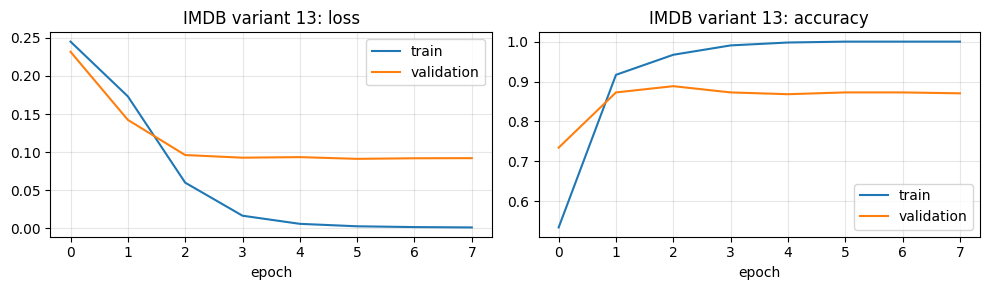

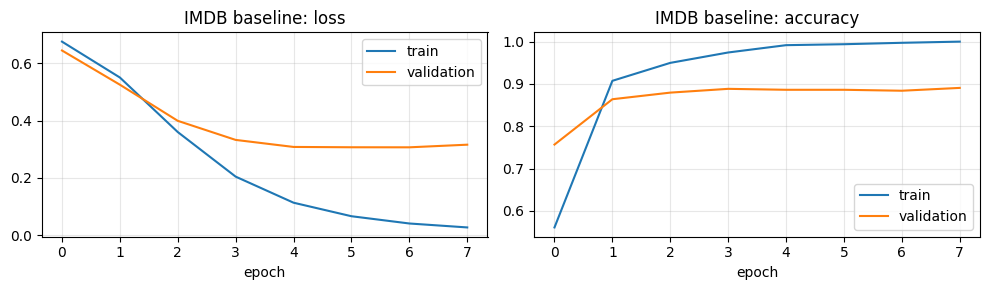

In [7]:
def column(values: np.ndarray) -> np.ndarray:
    return values.reshape(-1, 1).astype("float32")

imdb_model = nn.Sequential(
    make_mlp(x_train.shape[1], [16, 32, 16], ["relu", "relu", "tanh"], 1),
    nn.Sigmoid(),
)
imdb_baseline = make_mlp(x_train.shape[1], [16, 16], ["relu", "relu"], 1)

train_loader = make_loader(x_train, column(y_train), batch_size=64)
val_loader = make_loader(x_val, column(y_val), batch_size=128, shuffle=False)
test_loader = make_loader(x_test, column(y_test), batch_size=128, shuffle=False)

imdb_history = train_model(
    imdb_model, train_loader, val_loader, nn.MSELoss(), task="binary_probability", epochs=8
)
baseline_history = train_model(
    imdb_baseline, train_loader, val_loader, nn.BCEWithLogitsLoss(), task="binary", epochs=8
)

imdb_loss, imdb_acc = evaluate(imdb_model, test_loader, nn.MSELoss(), "binary_probability")
base_loss, base_acc = evaluate(imdb_baseline, test_loader, nn.BCEWithLogitsLoss(), "binary")

print(f"IMDB variant: test_loss={imdb_loss:.4f}, test_acc={imdb_acc:.4f}")
print(f"IMDB baseline: test_loss={base_loss:.4f}, test_acc={base_acc:.4f}")

plot_history(imdb_history, "IMDB variant 13")
plot_history(baseline_history, "IMDB baseline")


## Этап 2. Многоклассовая классификация Reuters

Используется локальный файл `data/reuters.npz`, скачанный заранее. В ноутбуке скачивания нет: код только читает готовый датасет.


Reuters train/val/test: 7185/1797/2246
Reuters classes: 46
Multiclass variant: test_loss=1.7662, test_acc=0.7467
Multiclass baseline: test_loss=1.2525, test_acc=0.7760


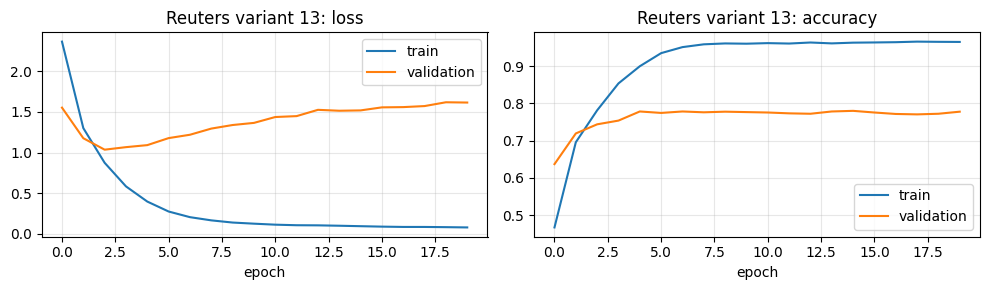

In [8]:
reuters_path = local_dataset_file("reuters.npz")

with np.load(reuters_path, allow_pickle=True) as data:
    reuters_sequences = data["x"]
    reuters_labels = data["y"].astype("int64")

# Повторяем стандартную схему keras.datasets.reuters.load_data: перемешивание с seed=113
# и разделение 80/20 на train/test.
indices = np.arange(len(reuters_sequences))
rng = np.random.default_rng(113)
rng.shuffle(indices)
reuters_sequences = reuters_sequences[indices]
reuters_labels = reuters_labels[indices]

split = int(len(reuters_sequences) * 0.8)
x_train_seq = reuters_sequences[:split]
y_train_full = reuters_labels[:split]
x_test_seq = reuters_sequences[split:]
y_test = reuters_labels[split:]

NUM_WORDS = 10000


def vectorize_sequences(sequences, dimension: int = NUM_WORDS) -> np.ndarray:
    result = np.zeros((len(sequences), dimension), dtype="float32")
    for row, sequence in enumerate(sequences):
        indexes = [index for index in sequence if index < dimension]
        result[row, indexes] = 1.0
    return result


x_train_full = vectorize_sequences(x_train_seq)
x_test = vectorize_sequences(x_test_seq)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=SEED
)

num_classes = int(max(y_train_full.max(), y_test.max()) + 1)
multi_model = make_mlp(x_train.shape[1], [32, 64, 64], ["tanh", "mish", "relu"], num_classes)
multi_baseline = make_mlp(x_train.shape[1], [64, 64], ["relu", "relu"], num_classes)
criterion = nn.CrossEntropyLoss()

multi_history = train_model(
    multi_model,
    make_loader(x_train, y_train, batch_size=64),
    make_loader(x_val, y_val, batch_size=128, shuffle=False),
    criterion,
    task="multiclass",
    epochs=20,
)
train_model(
    multi_baseline,
    make_loader(x_train, y_train, batch_size=64),
    make_loader(x_val, y_val, batch_size=128, shuffle=False),
    criterion,
    task="multiclass",
    epochs=20,
)

multi_loss, multi_acc = evaluate(multi_model, make_loader(x_test, y_test, batch_size=128, shuffle=False), criterion, "multiclass")
base_loss, base_acc = evaluate(multi_baseline, make_loader(x_test, y_test, batch_size=128, shuffle=False), criterion, "multiclass")

print(f"Reuters train/val/test: {len(x_train)}/{len(x_val)}/{len(x_test)}")
print(f"Reuters classes: {num_classes}")
print(f"Multiclass variant: test_loss={multi_loss:.4f}, test_acc={multi_acc:.4f}")
print(f"Multiclass baseline: test_loss={base_loss:.4f}, test_acc={base_acc:.4f}")

plot_history(multi_history, "Reuters variant 13")


## Этап 3. Boston Housing: регрессия с проверкой по K блокам

Используется локальный файл `data/boston_housing.npz`, скачанный заранее. Вариант 13 содержит три скрытых слоя, поэтому используется `K=4`.


Boston Housing samples/features: 506/13
Regression KFold MAE: [2.82, 2.64, 3.28, 3.01], mean=2.94
Regression baseline MAE: [2.89, 2.75, 2.82, 2.62], mean=2.77


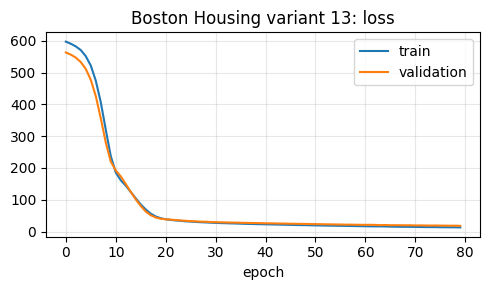

In [9]:
boston_path = local_dataset_file("boston_housing.npz")

with np.load(boston_path) as data:
    x = data["x"].astype("float32")
    y = data["y"].astype("float32").reshape(-1, 1)

x = StandardScaler().fit_transform(x).astype("float32")

kfold = KFold(n_splits=4, shuffle=True, random_state=SEED)
fold_mae = []
baseline_mae = []
first_fold_history = None

for fold, (train_idx, val_idx) in enumerate(kfold.split(x), start=1):
    reg_model = make_mlp(x.shape[1], [32, 64, 64], ["tanh", "mish", "relu"], 1)
    reg_baseline = make_mlp(x.shape[1], [64, 64], ["relu", "relu"], 1)
    criterion = nn.MSELoss()

    train_loader = make_loader(x[train_idx], y[train_idx], batch_size=32)
    val_loader = make_loader(x[val_idx], y[val_idx], batch_size=32, shuffle=False)

    history = train_model(reg_model, train_loader, val_loader, criterion, task="regression", epochs=80, lr=5e-4)
    train_model(reg_baseline, train_loader, val_loader, criterion, task="regression", epochs=80, lr=5e-4)

    reg_model.eval()
    reg_baseline.eval()
    with torch.no_grad():
        val_tensor = torch.tensor(x[val_idx], dtype=torch.float32, device=DEVICE)
        pred = reg_model(val_tensor).cpu().numpy()
        base_pred = reg_baseline(val_tensor).cpu().numpy()

    fold_mae.append(float(np.mean(np.abs(pred - y[val_idx]))))
    baseline_mae.append(float(np.mean(np.abs(base_pred - y[val_idx]))))

    if first_fold_history is None:
        first_fold_history = history

print(f"Boston Housing samples/features: {x.shape[0]}/{x.shape[1]}")
print(f"Regression KFold MAE: {np.round(fold_mae, 2).tolist()}, mean={np.mean(fold_mae):.2f}")
print(f"Regression baseline MAE: {np.round(baseline_mae, 2).tolist()}, mean={np.mean(baseline_mae):.2f}")

plot_history(first_fold_history, "Boston Housing variant 13", show_accuracy=False)
